# Task 2: Forecasting a week of demand and import

> **This is the solution notebook.** Every `# TODO` is filled in and every question has a model answer. The student version is `task_2_analysis.ipynb`.

In this task you'll forecast the final week of data with two models, measure how good each forecast is, and decide which model is better.

**Plan**

1. Load the hourly data from Task 1 and split off the last week as a test set.
2. A quick introduction to SARIMAX, the model family we use.
3. Method 1: seasonal SARIMA.
4. Method 2: SARIMAX with Fourier terms.
5. Plot the forecasts against what actually happened.
6. Write the error metrics MAE, RMSE and MAPE, and use them to pick a winner.
7. Repeat for Import.

**What we give you:** the model settings (hyperparameters), and helper functions in `src/task_helpers.py` that build, fit and run the models. You don't need to change that file, but feel free to read it.

**What you do:** fill in a few settings, write the error metrics, make the plots, and interpret the results.

The notebook conventions are the same as in Task 1: **`# TODO`** cells for you to complete, **Check** cells that test your work, and **Question** cells to answer. Fitting a model can take up to a minute.

In [1]:
import warnings
warnings.filterwarnings('ignore')   # hide statsmodels' fitting warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import src.task_helpers as th

## 1. Load and split the data

`TARGET` chooses which series to forecast. Start with `'Demand'`. You'll switch to `'Import'` in step 7.

In [2]:
TARGET = 'Import'   # 'Demand' or 'Import'

In [3]:
data = th.load_data('data/forecast_preproc_task.csv')
print(len(data), 'hourly rows, from', data.index.min(), 'to', data.index.max())

2664 hourly rows, from 2020-12-01 00:00:00 to 2021-03-21 23:00:00


The task is to **train on everything except the final week**, and use that week as the **test set**. The model never sees the test week while it's being fitted. That's what makes this a fair test: it's like forecasting the future and then checking what really happened.

In [4]:
# A week is 7 days of 24 hourly readings
HOURS_IN_TEST = 7 * 24

train, test = th.split_train_test(data, n_test=HOURS_IN_TEST)
print('Train:', train.index.min(), 'to', train.index.max(), f'({len(train)} hours)')
print('Test: ', test.index.min(), 'to', test.index.max(), f'({len(test)} hours)')

Train: 2020-12-01 00:00:00 to 2021-03-14 23:00:00 (2496 hours)
Test:  2021-03-15 00:00:00 to 2021-03-21 23:00:00 (168 hours)


In [5]:
# Check (don't edit me)
assert HOURS_IN_TEST == 168, f'A week of hourly data is 7 * 24 = 168 points, not {HOURS_IN_TEST}.'
assert len(test) == 168, f'Test set should be 168 hours, got {len(test)}.'
assert len(train) + len(test) == len(data), 'Train and test should together cover all the data.'
print('Looks good.')

Looks good.


Before modelling, look at the patterns you're trying to capture. Here are the last three weeks of training data.

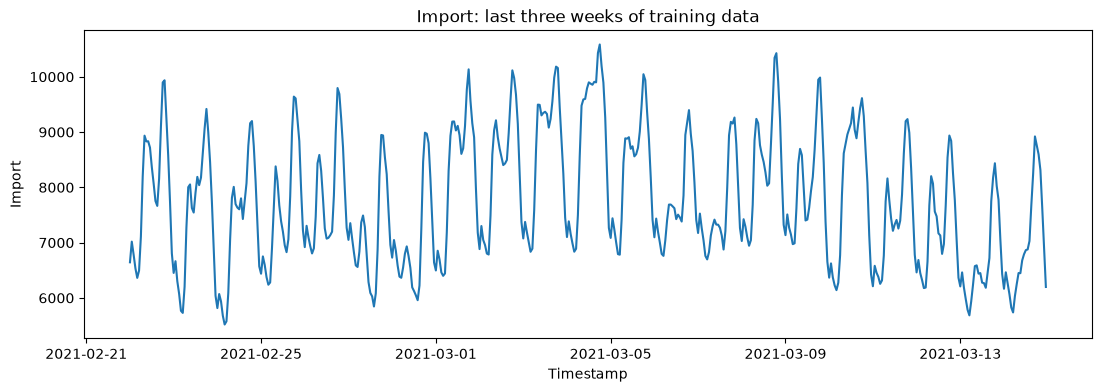

In [6]:
recent = train[TARGET].iloc[-21 * 24:]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(recent.index, recent)
ax.set_title(f'{TARGET}: last three weeks of training data')
ax.set_xlabel('Timestamp')
ax.set_ylabel(TARGET)
plt.show()

**Question 1.** Look at the plot above.

- What are the dominant rhythms (repeating patterns) you can see?
- For each rhythm, how many data points make up one full period of it?

*Answer:* There are two clear rhythms. A **daily** cycle (a peak and a trough every day), one period of which is **24** hourly points. And a **weekly** cycle (weekends sit lower than weekdays), one period of which is `7 * 24 =` **168** hourly points.

*Your answer:*

## 2. A quick introduction to SARIMAX

SARIMAX is a family of models that forecast a series from its own recent past. The name is a stack of ideas, one per letter. You don't need the maths, just the intuition:

| Letter | Name | The idea | Setting |
|---|---|---|---|
| **AR** | AutoRegressive | The next value depends on the last few values: "demand now is a lot like demand an hour ago". | `p`: how many past values to use |
| **I** | Integrated | Model the *change* from one step to the next instead of the level. This removes slow drifts. | `d`: how many times to take differences |
| **MA** | Moving Average | Learn from recent mistakes: if the last few forecasts were too low, nudge the next one up. | `q`: how many past errors to use |
| **S** | Seasonal | The same three ideas, but looking back one whole *season*: "demand now is like demand at this time yesterday". | `P`, `D`, `Q`, plus `s`, the season length in time steps |
| **X** | eXogenous | Extra input columns that help explain the series. | the columns you pass in as `exog` |

A model is written **SARIMAX(p, d, q)(P, D, Q, s)**. *Fitting* means statsmodels searches for the coefficients that best explain the training data.

Choosing `p, d, q, P, D, Q` well takes a lot of trial and error, so **we've done it for you**: we tried many combinations and kept the best. What's left for you is the part that depends on understanding the data: the length of the seasonal cycles.

Two more things worth knowing:

- SARIMAX copes with `NaN` gaps, which is why Task 1 didn't fill them.
- To forecast a week ahead, the model rolls forward from the end of the training data, feeding its own predictions back in. The further ahead it goes, the more it relies on the seasonal pattern and the less on recent observations.

More details:
- https://www.geeksforgeeks.org/python/complete-guide-to-sarimax-in-python/

In [7]:
# Chosen for you from an earlier search. Don't change these.
BEST_PARAMS = {
    'Demand': {'method1_order': (2, 1, 2), 'method1_seasonal_PDQ': (2, 1, 1), 'method2_order': (3, 2, 2)},
    'Import': {'method1_order': (2, 1, 2), 'method1_seasonal_PDQ': (1, 1, 2), 'method2_order': (3, 2, 3)},
}
params = BEST_PARAMS[TARGET]
params

{'method1_order': (2, 1, 2),
 'method1_seasonal_PDQ': (1, 1, 2),
 'method2_order': (3, 2, 3)}

## 3. Method 1: Seasonal SARIMA

Method 1 uses the **S** part of SARIMAX to capture the daily cycle. You need to supply `s`: the number of time steps in one daily cycle, for hourly data (one of the numbers from Question 1).

If fitting takes more than a couple of minutes, check your value of `s`.

In [8]:
# A daily cycle is 24 hourly points
SEASON_LENGTH = 24

order = params['method1_order']
seasonal_order = params['method1_seasonal_PDQ'] + (SEASON_LENGTH,)
print('Method 1: SARIMAX', order, seasonal_order)

Method 1: SARIMAX (2, 1, 2) (1, 1, 2, 24)


In [9]:
# Fit on the training data, then forecast the test week (takes up to a minute)
fit1 = th.fit_seasonal_sarima(train[TARGET], order, seasonal_order)
pred1 = th.forecast(fit1, test.index)
pred1.head()

2021-03-15 00:00:00    5957.349973
2021-03-15 01:00:00    6274.467355
2021-03-15 02:00:00    6053.454199
2021-03-15 03:00:00    5857.656966
2021-03-15 04:00:00    5658.810733
Freq: h, Name: forecast, dtype: float64

> **Tip:** `pred1` is already a full forecast of the test week. If you'd like to see how you're doing, feel free to jump ahead to **step 5** and plot `pred1` against the actual values now, before building the second model. You can come back here afterwards.

**Question 2.** Method 1 captures seasonality by looking back exactly one season, and you set the season length to one **day**.

So the model's notion of "the usual pattern" repeats every 24 hours and is the same on every day of the week. Given that, do you expect it to capture the difference between weekdays and weekends that you saw in Question 1? Why or why not?

*Answer:* No. With a 24-hour season the model only knows one "typical day" and repeats it. It has no sense of which day of the week it is, so it can't lower its forecast for weekends. (We could instead use a weekly season of 168, but that is a much larger, slower model. Method 2 handles the weekly pattern a cheaper way.)

*Your answer:*

## 4. Method 2: SARIMAX with Fourier terms

Method 2 drops the seasonal part. Instead, it gives the model smooth repeating waves as extra input columns: the **X** in SARIMAX.

**Fourier terms.** For a cycle with period $T$ time steps, the Fourier terms are pairs of waves

$$\sin\left(\frac{2\pi k t}{T}\right), \quad \cos\left(\frac{2\pi k t}{T}\right), \qquad k = 1, 2, \dots, K$$

With $k = 1$ there's one smooth bump per cycle. Higher $k$ adds faster wiggles, so a weighted mix of a few of them can match almost any repeating shape. The model learns the weights. We use $K = 3$, which gives 6 columns per cycle.

We add **two** cycles: a daily one and a weekly one. The weekly cycle is what lets this model tell weekdays from weekends.

**DeterministicProcess** is the statsmodels tool that builds these columns for a set of timestamps. *Deterministic* means the values are known exactly for any time, including the future. That matters: to forecast the test week, SARIMAX needs the extra columns for the test week too. The test-week columns must carry on from where the training columns stopped, rather than starting again from $t = 0$. Otherwise the waves would be out of step (training starts on a Tuesday, the test week on a Monday). The helper `make_fourier_terms` takes care of this for you.

Your job: set the period of each cycle, in hours (the two numbers from Question 1).

In [10]:
# One day and one week, in hours
DAILY_PERIOD = 24
WEEKLY_PERIOD = 24 * 7

fourier_train, fourier_test = th.make_fourier_terms(
    train.index, test.index, daily_period=DAILY_PERIOD, weekly_period=WEEKLY_PERIOD)
fourier_train.head()

,const,"sin(1,24)","cos(1,24)","sin(2,24)","cos(2,24)","sin(3,24)","cos(3,24)","sin(1,168)","cos(1,168)","sin(2,168)","cos(2,168)","sin(3,168)","cos(3,168)"
Timestamp,,,,,,,,,,,,,
2020-12-01 00:00:00,1.0,0.000000,1.000000,0.000000,1.000000e+00,0.000000e+00,1.000000e+00,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
2020-12-01 01:00:00,1.0,0.258819,0.965926,0.500000,8.660254e-01,7.071068e-01,7.071068e-01,0.037391,0.999301,0.074730,0.997204,0.111964,0.993712
2020-12-01 02:00:00,1.0,0.500000,0.866025,0.866025,5.000000e-01,1.000000e+00,6.123234e-17,0.074730,0.997204,0.149042,0.988831,0.222521,0.974928
2020-12-01 03:00:00,1.0,0.707107,0.707107,1.000000,6.123234e-17,7.071068e-01,-7.071068e-01,0.111964,0.993712,0.222521,0.974928,0.330279,0.943883
2020-12-01 04:00:00,1.0,0.866025,0.500000,0.866025,-5.000000e-01,1.224647e-16,-1.000000e+00,0.149042,0.988831,0.294755,0.955573,0.433884,0.900969


Plot a few of the Fourier columns over the first two weeks of training. The daily waves should repeat once a day, and the weekly wave once a week.

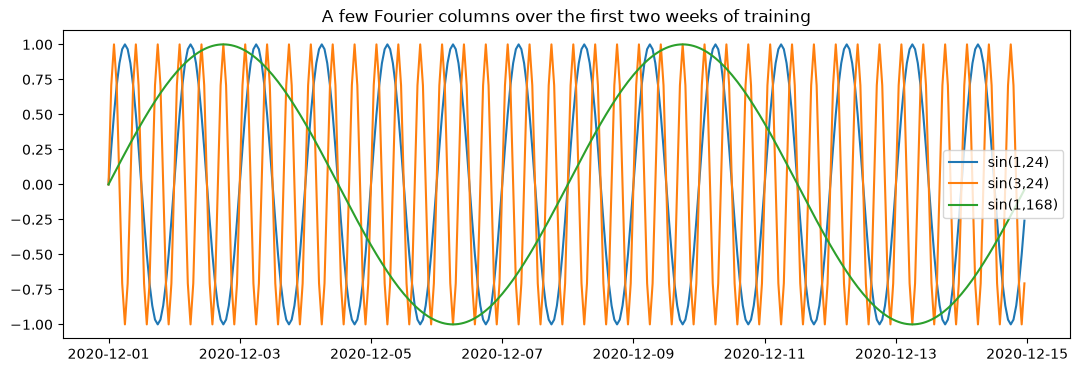

In [11]:
first_two_weeks = fourier_train.iloc[:14 * 24]
columns = [fourier_train.columns[1], fourier_train.columns[5], fourier_train.columns[7]]

fig, ax = plt.subplots(figsize=(13, 4))
for column in columns:
    ax.plot(first_two_weeks.index, first_two_weeks[column], label=column)
ax.set_title('A few Fourier columns over the first two weeks of training')
ax.legend()
plt.show()

In [12]:
# Fit on the training data, then forecast the test week
fit2 = th.fit_fourier_sarimax(train[TARGET], params['method2_order'], fourier_train)
pred2 = th.forecast(fit2, test.index, fourier_test)
pred2.head()

/Users/dgalvis/.pyenv/versions/3.12.13/envs/task_env/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/Users/dgalvis/.pyenv/versions/3.12.13/envs/task_env/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


2021-03-15 00:00:00    5804.420747
2021-03-15 01:00:00    5743.712963
2021-03-15 02:00:00    5684.910431
2021-03-15 03:00:00    5642.501318
2021-03-15 04:00:00    5569.430758
Freq: h, Name: forecast, dtype: float64

## 5. Plot the forecasts

Plot the actual values for the test week together with both forecasts, on the same axes. Give each line a `label` and add a legend. Optionally, also show the last few days of training data for context.

*Hint:* `ax.plot(test.index, test[TARGET], label='actual')`. `pred1` and `pred2` are Series with the same timestamps.

(If you jumped here from step 3 with only `pred1`, just plot `pred1` for now and add `pred2` once you've built it.)

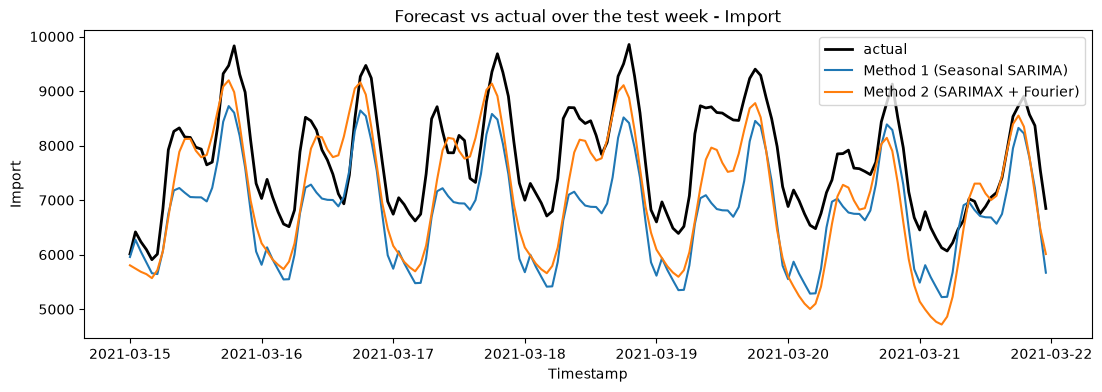

In [13]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(test.index, test[TARGET], color='black', linewidth=2, label='actual')
ax.plot(pred1.index, pred1, label='Method 1 (Seasonal SARIMA)')
ax.plot(pred2.index, pred2, label='Method 2 (SARIMAX + Fourier)')
ax.set_title(f'Forecast vs actual over the test week - {TARGET}')
ax.set_xlabel('Timestamp')
ax.set_ylabel(TARGET)
ax.legend()
plt.show()

**Question 3.**

- Which forecast follows the actual values more closely?
- Do both get the daily shape right? What about the weekend?
- Is either forecast consistently too high or too low (a *bias*)?

*Answer:* Method 2 follows the actual values more closely. Both capture the daily shape well, but only Method 2 pulls its forecast down over the weekend, as expected from Question 2. Both tend to sit a little below the actual values (a mild low bias), with Method 1 the more noticeably low of the two.

*Your answer:*

## 6. How good is each forecast?

A plot gives a feel for the forecast. Metrics give a number you can compare. For each hour $t$ of the test week, the error is $e_t = \text{actual}_t - \text{predicted}_t$, and there are $n$ hours in total.

- **MAE**, mean absolute error: the average size of a miss, in the same units as the data.
$$\text{MAE} = \frac{1}{n} \sum_t |e_t|$$
- **RMSE**, root mean squared error: squares the errors first, so big misses count for more. It's always at least as large as the MAE.
$$\text{RMSE} = \sqrt{\frac{1}{n} \sum_t e_t^2}$$
- **MAPE**, mean absolute percentage error: the average miss as a percentage of the actual value. Because it has no units, you can compare it across series of different sizes, such as Demand and Import. It breaks down when actual values are close to zero.
$$\text{MAPE} = \frac{100}{n} \sum_t \left|\frac{e_t}{\text{actual}_t}\right|$$

For all three, **lower is better**.

Write each one as a function. *Hint:* `np.abs`, `np.mean` and `np.sqrt` are all you need. Calling `np.asarray` on the inputs first makes your functions work for lists, arrays and Series alike.

In [14]:
def mae(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    return np.mean(np.abs(actual - predicted))


def rmse(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    return np.sqrt(np.mean((actual - predicted) ** 2))


def mape(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    return np.mean(np.abs((actual - predicted) / actual)) * 100

In [15]:
# Check: a tiny example you can work out by hand
actual_toy = np.array([100.0, 200.0])
predicted_toy = np.array([110.0, 180.0])   # errors are -10 and +20

assert np.isclose(mae(actual_toy, predicted_toy), 15.0), 'mae should be (10 + 20) / 2 = 15'
assert np.isclose(rmse(actual_toy, predicted_toy), np.sqrt(250)), 'rmse should be sqrt((100 + 400) / 2), about 15.81'
assert np.isclose(mape(actual_toy, predicted_toy), 10.0), 'mape should be (10% + 10%) / 2 = 10'
print('All three metrics pass.')

All three metrics pass.


In [16]:
results = pd.DataFrame({
    'Method 1 (Seasonal SARIMA)': [f(test[TARGET], pred1) for f in (mae, rmse, mape)],
    'Method 2 (SARIMAX + Fourier)': [f(test[TARGET], pred2) for f in (mae, rmse, mape)],
}, index=['MAE', 'RMSE', 'MAPE (%)']).T.round(2)

print('Target:', TARGET)
results

Target: Import


,MAE,RMSE,MAPE (%)
Method 1 (Seasonal SARIMA),986.94,1073.00,12.70
Method 2 (SARIMAX + Fourier),779.46,902.97,10.33


**Question 4.**

- Which model is better for this target? Do all three metrics agree?
- Using your answers to questions 2 and 3, why do you think that model did better?

*Answer:* For Demand, **Method 2** is better, and all three metrics agree (MAE, RMSE and MAPE are all lower). It wins because its weekly Fourier term lets it lower the forecast on weekends, which Method 1's daily-only season cannot do (Questions 2 and 3).

*Your answer:*

## 7. Repeat for Import

Go back to step 1, set `TARGET = 'Import'`, and run all the cells again from the top. Then record both sets of results here.

| Target | Method 1: MAE / RMSE / MAPE | Method 2: MAE / RMSE / MAPE | Best model |
|---|---|---|---|
| Demand | 653 / 734 / 7.4% | 381 / 474 / 4.4% | Method 2 |
| Import | 987 / 1073 / 12.7% | 779 / 903 / 10.3% | Method 2 |

*(Your numbers may differ by a little depending on the optimiser.)*

**Question 5.**

1. Which model would you recommend for each target, and why?
2. Compare the MAPE for Demand with the MAPE for Import. Which series is harder to forecast?
3. We judged the models on a single week. Why is that risky? How could you make the comparison more reliable?
4. What extra data might improve these forecasts?

*Answer:*
1. **Method 2** for both targets: it has the lower error on every metric, mainly thanks to the weekly pattern.
2. Import has the higher MAPE (about 10% vs about 4%), so it is **harder** to forecast.
3. A single week could be unusually easy or hard (weather, a holiday, an event), so the ranking might not hold on another week. A more reliable comparison tests several different weeks, for example with rolling or expanding-window backtesting, and averages the metrics.
4. Weather (temperature, wind speed, sunshine), calendar effects (holidays, weekday vs weekend, school terms), and electricity price would all likely help, especially for Import, which depends on wind and solar generation.

*Your answer:*